# Baja Data Analysis - Tachometer (Hall-Effect Sensor HW-047 V0.2)

There are a total of 2 channel (CH6-CH7) measuring instantaneous RPM of the vehicle using HW-047 V0.2 Hall-Effect Sensor. The data will be measured each 0.0165s (16.5ms)
<br/>
Currently, the file will measure:
<ul>
    <li>RPM of CH6, CH7</li>
    <li>Frequency of CH6, CH7</li>
    <li>Voltage of CH6, CH7</li>
    <li>Max, min voltage in CH6 and CH7</li>
<ul>

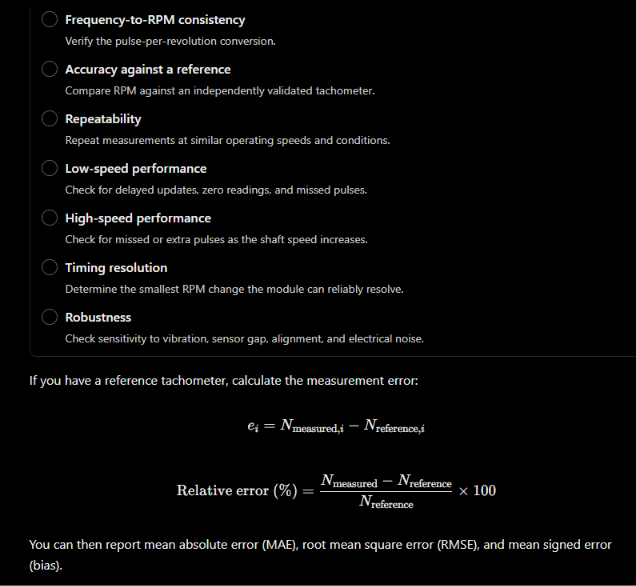

### Others:

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import csv
import plotly.express as px
import ipywidgets as widgets
from IPython.display import display
from matplotlib.widgets import Button, RadioButtons
from scipy.signal import butter, filtfilt

In [2]:
# All data type must be float 64

tachometer_df = pd.read_csv('data/Hat1_Tachometer_Acquisition1_09-10-2026.csv', dtype= {
    'elapsed_s' : 'float64',
    'CH6_voltage_V' : 'float64',
    'CH6_frequency_Hz' : 'float64',
    'CH6_rpm' : 'float64',
    'CH7_voltage_V' : 'float64',
    'CH7_frequency_Hz' : 'float64',
    'CH7_rpm' : 'float64',
})

tachometer_df

,elapsed_s,CH6_voltage_V,CH6_frequency_Hz,CH6_rpm,CH7_voltage_V,CH7_frequency_Hz,CH7_rpm
0,0.0000,0.002299,0.031,1.854,0.001374,0.018,1.108
1,0.0165,0.002299,0.031,1.854,0.000140,0.002,0.113
2,0.0330,0.003225,0.043,2.601,0.001682,0.023,1.357
3,0.0495,0.003225,0.043,2.601,0.001374,0.018,1.108
4,0.0660,0.002917,0.039,2.352,0.001065,0.014,0.859
...,...,...,...,...,...,...,...
48510,800.4150,0.006310,0.085,5.089,0.002917,0.039,2.352
48511,800.4315,0.005693,0.077,4.591,0.001991,0.027,1.606
48512,800.4480,0.006310,0.085,5.089,0.002917,0.039,2.352
48513,800.4645,0.005385,0.072,4.343,0.001682,0.023,1.357


In [3]:
# All the data type of float64
IR_df = pd.read_csv('data/Hat1_IR_Sensor_Acquisition1_09-10-2026.csv', dtype = {
    "elapsed_s" : "float64",
    "voltage_V" : "float64",
    "temp_C" : "float64",
    "temp_F" : "float64",
    "warning_C" : "float64",
    "warning_F" : "float64",
    "critical_C" : "float64",
    "critical_F" : "float64",
})
# Showing data
IR_df

slicing_IR_corrupted = 4968

slicing_IR_df = IR_df.iloc[0: slicing_IR_corrupted]

slicing_IR_df

,elapsed_s,voltage_V,temp_C,temp_F,warning_C,warning_F,critical_C,critical_F
0,0.0,1.036792,50.9035,123.6262,0.0,0.0,0.0,0.0
1,0.1,1.037101,50.9421,123.6957,0.0,0.0,0.0,0.0
2,0.2,1.036484,50.8648,123.5567,0.0,0.0,0.0,0.0
3,0.3,1.035867,50.7876,123.4178,0.0,0.0,0.0,0.0
4,0.4,1.038335,51.0965,123.9736,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...
4963,496.3,1.102200,59.0873,138.3571,0.0,0.0,0.0,0.0
4964,496.4,1.103434,59.2417,138.6350,0.0,0.0,0.0,0.0
4965,496.5,1.103434,59.2417,138.6350,0.0,0.0,0.0,0.0
4966,496.6,1.103126,59.2031,138.5656,0.0,0.0,0.0,0.0


In [4]:
tachometer_df.describe()

slicing_corrupted = 48515
slicing_df = tachometer_df.iloc[0:slicing_corrupted]

### VOLTAGE RANGE (FOR EASIER VIEWING)

In [5]:
slicing_voltage_6_df = slicing_df['CH6_voltage_V']
slicing_voltage_7_df = slicing_df['CH7_voltage_V']



### Tachometer + IR Sensor Combining

In [6]:
slice_tachometer_compare = 24244
slice_IR_compare = 4001

slice_IR_compare_df = slicing_IR_df.iloc[0:slice_IR_compare]
slice_tachometer_compare = slicing_df.iloc[0:slice_tachometer_compare]

### Compare: CH7_rpm, CH6_rpm, temp_C, temp_F

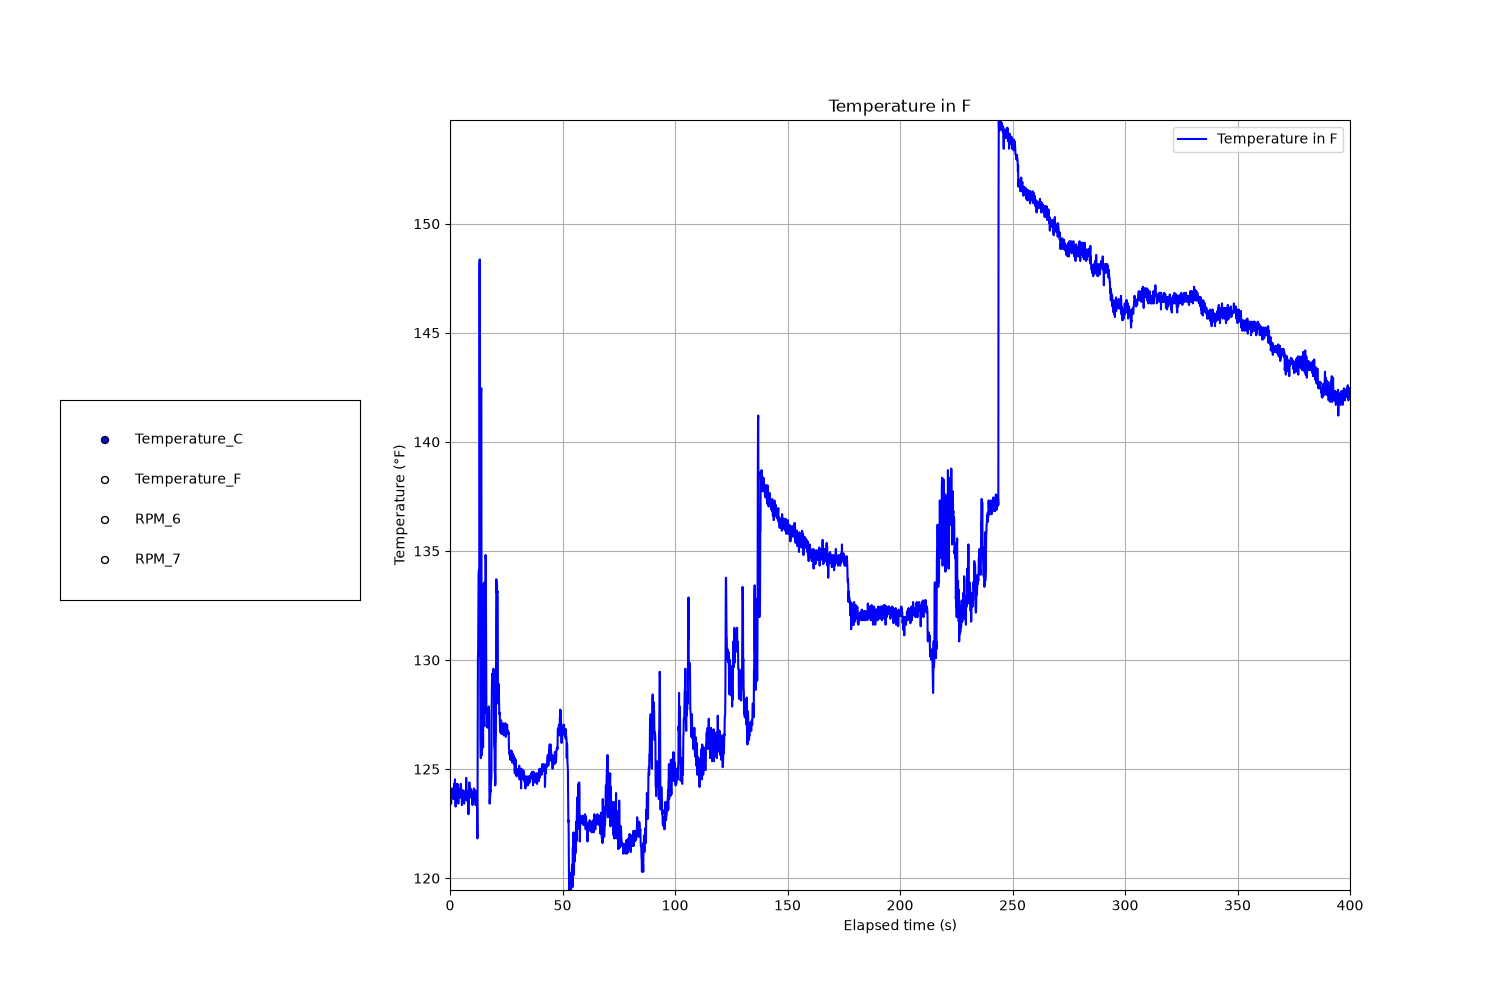

In [7]:
%matplotlib widget

def moving_average_filter(data, window_size):
    window = np.ones(window_size) / window_size
    return np.convolve(data, window, mode='same')

def lowpass_filter(data, cutoff_freq, fs, order = 4):
    nyquist = 0.5 * fs # fixed according to sampling theory

    normal_cutoff= cutoff_freq / nyquist

    b, a = butter(order, normal_cutoff, btype='low', analog=False)
    
    # Apply the filter forward and backward using filtfilt to eliminate phase shift
    filtered_data = filtfilt(b, a, data)
    
    return filtered_data

slice_tachometer_compare = 24244
slice_IR_compare = 4001

slice_IR_compare_df = slicing_IR_df.iloc[0:slice_IR_compare]
slice_tachometer_compare = slicing_df.iloc[0:slice_tachometer_compare]

slicing_temperature_C = slice_IR_compare_df['temp_C']
slicing_temperature_F = slice_IR_compare_df['temp_F']

slicing_RPM_7 = slice_tachometer_compare['CH7_rpm']
slicing_RPM_6 = slice_tachometer_compare['CH6_rpm']

slicing_IR_time = slice_IR_compare_df['elapsed_s']
slicing_tachometer_time = slice_tachometer_compare['elapsed_s']

fig, ax = plt.subplots(figsize = (15,10))
plt.subplots_adjust(left = 0.30)

radio_ax = fig.add_axes([0.04, 0.40, 0.2, 0.2])
radio = RadioButtons(radio_ax, ("Temperature_C", "Temperature_F", "RPM_6", "RPM_7"))

def show_graph(label):

    data_display = {
        "Temperature_C": {
            "xlabel": "Elapsed time (s)",
            "ylabel": "Temperature (°C)",
            "xdf": slicing_IR_time,
            "ydf": slicing_temperature_C,
            "title": "Temperature in C",
        },
        "Temperature_F": {
            "xlabel": "Elapsed time (s)",
            "ylabel": "Temperature (°F)",
            "xdf": slicing_IR_time,
            "ydf": slicing_temperature_F,
            "title": "Temperature in F",
        },
        "RPM_6": {
            "xlabel": "Elapsed time (s)",
            "ylabel": "RPM Channel 6",
            "xdf": slicing_tachometer_time,
            "ydf": slicing_RPM_6,
            "title": "RPM Channel 6",
            "filtered_data" : lowpass_filter(slicing_RPM_6, 0.005, 2, order = 4),
        },
        "RPM_7": {
            "xlabel": "Elapsed time (s)",
            "ylabel": "RPM Channel 7",
            "xdf": slicing_tachometer_time,
            "ydf": slicing_RPM_7,
            "title": "RPM Channel 7",
            "filtered_data" : lowpass_filter(slicing_RPM_7, 0.005, 2, order = 4),
        },
    }

    value = data_display[label]

    ax.clear()
    ax.set_title(value['title'])
    ax.set_xlabel(value['xlabel'])
    ax.set_ylabel(value['ylabel'])
    ax.set_xlim(value['xdf'].min(), value['xdf'].max())
    ax.set_ylim(value['ydf'].min(), value['ydf'].max())
    ax.plot(value['xdf'], value['ydf'], label = value['title'], color = "blue")
    if (value.get('filtered_data') is not None):
        ax.plot(value['xdf'], value['filtered_data'], label = value['title'], color = "red")

    ax.grid(True)
    ax.legend()
    fig.canvas.draw_idle()

radio.on_clicked(show_graph)

show_graph("Temperature_F")

plt.show()